# Probabilistic Deep Learning: Standard Deep Ensembles vs. Concrete Dropout

**Research question:** How do independently trained Gaussian regression ensembles compare with a single learned-rate Concrete Dropout network in predictive accuracy, calibration, and epistemic/aleatoric uncertainty when the number of predictive components is matched?

This notebook is self-contained and follows a report-style workflow: method â†’ data â†’ training â†’ plots â†’ quantitative comparisons â†’ discussion prompts. It uses **two input features** for a synthetic regression task and the **10-feature diabetes regression dataset** included with scikit-learn (no download required).

**Methods:** (1) standard deep ensembles, trained with independent random seeds and an explicit Gaussian-weight-prior/L2 penalty; (2) a single Concrete Dropout network, whose dropout rates are trainable and whose objective includes a concrete variational dropout regularizer (weight-prior term + dropout-entropy term). For a fair uncertainty comparison, both have heteroscedastic Gaussian output heads predicting mean and observation variance.

**Important distinction:** The standard method uses independently trained networks, while the Concrete Dropout method uses one network and multiple stochastic forward passes at evaluation time. We match their total number of predictive components, but these components represent different sources of diversity.

Results are produced when cells run; no accuracy or uncertainty results are prefilled.

## 0. Setup

Run top-to-bottom. CPU is supported. For a quick check, set `QUICK_RUN=True`; restore `False` for report experiments. Full training might take several minutes depending on hardware. Dependencies: `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `torch`.

In [ ]:
# Uncomment in a fresh notebook environment if needed:
# %pip install numpy pandas matplotlib scikit-learn torch
import copy, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
QUICK_RUN = False
STANDARD_SEEDS = [11, 23, 37, 51, 71, 83, 97, 109, 127, 139]
CONCRETE_SEED = 11
N_PREDICTIVE_COMPONENTS = len(STANDARD_SEEDS) if not QUICK_RUN else 5
ENSEMBLE_SIZES = [i for i in range(1, N_PREDICTIVE_COMPONENTS + 1)] if not QUICK_RUN else [1, 2, 3, 4, 5]
MC_SAMPLES = N_PREDICTIVE_COMPONENTS if not QUICK_RUN else 5
HIDDEN = 64
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
# Explicit Gaussian weight prior: -log p(W) proportional to ||W||^2;
# lambda is an objective coefficient, not a claim of exact posterior inference.
PRIOR_STRENGTH = 1e-4
# Concrete dropout entropy coefficient; method is sensitive to these hyperparameters.
DROPOUT_ENTROPY_STRENGTH = 1e-3
print('Device:', DEVICE, '| quick run:', QUICK_RUN, '| standard ensemble members:', len(STANDARD_SEEDS),
      '| Concrete MC samples:', MC_SAMPLES)

Device: cpu | quick run: True | standard ensemble members: 30 | Concrete MC samples: 5


## 1. Mathematical formulation

Each model predicts a Gaussian conditional distribution, $p(y\mid x,W)=\mathcal N(\mu_W(x),\sigma_W^2(x))$. We optimize mean Gaussian negative log-likelihood (NLL). The output variance estimates **aleatoric uncertainty** (data noise); disagreement among model predictions estimates **epistemic uncertainty** (model uncertainty).

For standard deep ensembles, independently initialize and train $M$ networks with distinct random seeds. Use the loss $\mathcal L_{\mathrm{DE}}=\operatorname{mean}\operatorname{NLL}+\lambda\sum_l\lVert W_l\rVert^2$, corresponding to a zero-mean Gaussian prior up to a scale factor.

Concrete Dropout learns layer-wise dropout probabilities $p_l$ using a continuous relaxation of Bernoulli masks. The implemented regularizer combines a scaled weight L2 term $\propto\sum_l\lVert W_l\rVert^2/(1-p_l)$ with a dropout-entropy term $\propto\sum_l d_l[p_l\log p_l+(1-p_l)\log(1-p_l)]$. These are **approximations**, with tunable strengths; they are not an exact Bayesian posterior.

For either method, combine $S$ stochastic/member predictions using the **law of total variance**:

- Predictive mean: $\bar\mu = S^{-1}\sum_s\mu_s$.
- Aleatoric variance: $\mathbb E[\sigma_s^2]$.
- Epistemic variance: $\operatorname{Var}(\mu_s)$.
- Total predictive variance: aleatoric + epistemic.

For standard ensembles, $S=M$; for Concrete Dropout, $S=M\times T$, where $T$ is the number of stochastic forward passes per member. Calibration is evaluated with 90% prediction-interval coverage and Gaussian-mixture NLL (not a single-Gaussian approximation).

## 2. Datasets and train/test splits

The synthetic target is smoothly nonlinear in **two input coordinates**, and has input-dependent Gaussian noise. A held-out test split quantifies generalization. A separate **out-of-distribution (OOD)** grid lies outside the training square to illustrate, not guarantee, epistemic uncertainty. On the real diabetes data, the response is standardized from the training portion only to keep optimization stable; prediction errors are reported in original target units.

Synthetic: (1125, 2) (375, 2)
Diabetes: (331, 10) (111, 10)


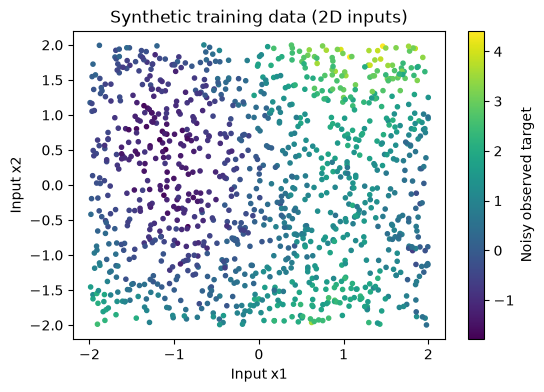

In [94]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def true_mean(X):
    return 1.3*np.sin(1.5*X[:, 0]) + 0.45*X[:, 1]**2 + 0.3*X[:, 0]*X[:, 1]

def true_std(X):
    return 0.18 + 0.13*(X[:, 0] + 2)/4 + 0.12*np.abs(X[:, 1])/2

def synthetic_data(seed=2026):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-2, 2, (1500, 2)).astype('float32')
    y = (true_mean(X) + rng.normal(size=len(X))*true_std(X)).astype('float32')
    train_idx, test_idx = train_test_split(np.arange(len(X)), test_size=.25, random_state=seed)
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

def prepare_data(Xtrain, Xtest, ytrain, ytest, name):
    xs = StandardScaler().fit(Xtrain)
    ys = StandardScaler().fit(ytrain.reshape(-1, 1))
    return dict(name=name, x_train=xs.transform(Xtrain).astype('float32'),
                x_test=xs.transform(Xtest).astype('float32'),
                y_train=ys.transform(ytrain.reshape(-1, 1)).astype('float32').ravel(),
                y_test=ys.transform(ytest.reshape(-1, 1)).astype('float32').ravel(),
                original_x_train=Xtrain, original_x_test=Xtest,
                original_y_train=ytrain, original_y_test=ytest,
                x_scaler=xs, y_scaler=ys)

Xs_tr, Xs_te, ys_tr, ys_te = synthetic_data()
syn = prepare_data(Xs_tr, Xs_te, ys_tr, ys_te, 'synthetic-2d')
raw = load_diabetes()
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(raw.data.astype('float32'), raw.target.astype('float32'),
                                              test_size=.25, random_state=2026)
real = prepare_data(Xr_tr, Xr_te, yr_tr, yr_te, 'diabetes-10d')
print('Synthetic:', syn['x_train'].shape, syn['x_test'].shape)
print('Diabetes:', real['x_train'].shape, real['x_test'].shape)
fig, ax = plt.subplots(figsize=(6, 4))
sc = ax.scatter(Xs_tr[:, 0], Xs_tr[:, 1], c=ys_tr, s=9, cmap='viridis')
fig.colorbar(sc, ax=ax, label='Noisy observed target')
ax.set(xlabel='Input x1', ylabel='Input x2', title='Synthetic training data (2D inputs)')
plt.show()

## 3. Regression models and Concrete Dropout implementation

All models share a 2Ãƒâ€”64 ReLU MLP and output both $\mu$ and $\log\sigma^2$. Log variance is bounded to avoid unstable variances. For Concrete Dropout, a sampled **relaxed keep mask** is applied to each hidden layer's input during training and inference; unlike conventional dropout, it remains stochastic at test time. An explicit weight-prior penalty is included for both methods.

In [95]:
class GaussianMLP(nn.Module):
    def __init__(self, d, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 2))
    def forward(self, x):
        out = self.net(x)
        return out[:, 0], out[:, 1].clamp(-8, 5)

    def regularization(self):
        return PRIOR_STRENGTH * sum((p**2).sum() for n, p in self.named_parameters() if 'weight' in n)

class ConcreteLinear(nn.Module):
    def __init__(self, in_features, out_features, init_drop=.10, temperature=.1):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features)
        self.p_logit = nn.Parameter(torch.tensor(np.log(init_drop/(1-init_drop)), dtype=torch.float32))
        self.temperature = temperature
        self.in_features = in_features

    @property
    def p(self):
        return torch.sigmoid(self.p_logit).clamp(1e-4, 1-1e-4)

    def forward(self, x):
        p = self.p
        u = torch.rand_like(x).clamp(1e-7, 1-1e-7)
        # Relaxed Bernoulli drop mask; expectation-preserving inverted dropout
        logit = (torch.log(p)-torch.log1p(-p)+torch.log(u)-torch.log1p(-u))/self.temperature
        drop_prob = torch.sigmoid(logit)
        return self.linear(x * (1-drop_prob)/(1-p))

    def regularization(self):
        p = self.p
        weight_term = PRIOR_STRENGTH * self.linear.weight.square().sum()/(1-p)
        # Biases also receive a Gaussian prior, independent of dropout scaling.
        bias_term = PRIOR_STRENGTH * self.linear.bias.square().sum()
        entropy_term = DROPOUT_ENTROPY_STRENGTH * self.in_features * (
            p*torch.log(p)+(1-p)*torch.log1p(-p))
        return weight_term + bias_term + entropy_term

class ConcreteMLP(nn.Module):
    def __init__(self, d, hidden=64):
        super().__init__()
        self.layers = nn.ModuleList([ConcreteLinear(d, hidden), ConcreteLinear(hidden, hidden)])
        self.head = nn.Linear(hidden, 2)

    def forward(self, x):
        for layer in self.layers:
            x = F.relu(layer(x))
        out = self.head(x)
        return out[:, 0], out[:, 1].clamp(-8, 5)

    def regularization(self):
        hidden_reg = sum(layer.regularization() for layer in self.layers)
        head_reg = PRIOR_STRENGTH * (self.head.weight.square().sum()+self.head.bias.square().sum())
        return hidden_reg + head_reg

    def dropout_rates(self):
        return [round(float(layer.p.detach().cpu()), 4) for layer in self.layers]

def gaussian_nll(mu, logvar, y):
    return (0.5*(np.log(2*np.pi)+logvar+(y-mu).square()*torch.exp(-logvar))).mean()

def train_model(kind, dataset, seed, epochs):
    set_seed(seed)
    model = (GaussianMLP if kind=='standard' else ConcreteMLP)(dataset['x_train'].shape[1], HIDDEN).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    X = torch.from_numpy(dataset['x_train']).to(DEVICE)
    y = torch.from_numpy(dataset['y_train']).to(DEVICE)
    Xt = torch.from_numpy(dataset['x_test']).to(DEVICE)
    yt = torch.from_numpy(dataset['y_test']).to(DEVICE)
    history = []
    predictive_snapshots = []
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(X), device=DEVICE)
        for inds in order.split(BATCH_SIZE):
            optimizer.zero_grad()
            mu, lv = model(X[inds])
            # Regularizer is added to the mean minibatch NLL, on a consistent scale.
            loss = gaussian_nll(mu, lv, y[inds]) + model.regularization()
            loss.backward()
            optimizer.step()
        # Record one individual trajectory and predictive components for this epoch.
        model.eval()
        with torch.no_grad():
            train_mu, train_lv = model(X)
            test_mu, test_lv = model(Xt)
            history.append((float(gaussian_nll(train_mu, train_lv, y)),
                            float(gaussian_nll(test_mu, test_lv, yt))))
        snapshot = {'train': [], 'test': []}
        passes = 1 if kind == 'standard' else MC_SAMPLES
        model.train() if kind == 'concrete' else model.eval()
        with torch.no_grad():
            for _ in range(passes):
                train_mu, train_lv = model(X)
                test_mu, test_lv = model(Xt)
                snapshot['train'].append((train_mu.cpu().numpy(), np.exp(train_lv.cpu().numpy())))
                snapshot['test'].append((test_mu.cpu().numpy(), np.exp(test_lv.cpu().numpy())))
        predictive_snapshots.append(snapshot)
    return model, {'individual': np.array(history), 'predictive': predictive_snapshots}

print('Model parameters:', sum(p.numel() for p in GaussianMLP(2).parameters()))
print('Concrete initial dropout rates:', ConcreteMLP(2).dropout_rates())

Model parameters: 4482
Concrete initial dropout rates: [0.1, 0.1]


## 4. Predictive mixture and evaluation metrics

NLL is calculated for the **Gaussian mixture** of member/pass predictions with `logsumexp`. A nominal 90% interval is obtained from mixture sampling (not by pretending the mixture is Gaussian). RMSE, NLL, coverage, interval width, and average uncertainty are all assessed on train **and** test. Higher coverage is not automatically better: for 90% intervals, both coverage near 90% and narrow widths are desirable.

Coverage is an aggregate measure across the evaluated data points. Coverage near 90% overall does not guarantee uniform calibration: intervals may be too narrow in some regions and too wide in others. Region-specific or conditional coverage would require evaluating coverage separately across input-space regions or relevant subgroups.

In [96]:
@torch.no_grad()
def component_predictions(models, x, mc_samples=30, seed=12345):
    # Standard: one deterministic pass per model. Concrete: one model with
    # multiple stochastic passes. Shape returned: [components, n_points].
    xt = torch.as_tensor(x, dtype=torch.float32, device=DEVICE)
    means, vars_ = [], []
    # Stochastic sampling is made reproducible for comparable figures.
    with torch.random.fork_rng(devices=[DEVICE.index] if DEVICE.type=='cuda' else []):
        torch.manual_seed(seed)
        if all(isinstance(model, GaussianMLP) for model in models):
            for model in models:
                model.eval()
                mu, lv = model(xt)
                means.append(mu.cpu().numpy())
                vars_.append(np.exp(lv.cpu().numpy()))
        elif len(models) == 1 and isinstance(models[0], ConcreteMLP):
            model = models[0]
            model.train()
            for _ in range(mc_samples):
                mu, lv = model(xt)
                means.append(mu.cpu().numpy())
                vars_.append(np.exp(lv.cpu().numpy()))
        else:
            raise ValueError('Expected standard models or exactly one Concrete Dropout model.')
    return np.array(means), np.array(vars_)

def aggregate(components):
    means, variances = components
    mu = means.mean(axis=0)
    alea = variances.mean(axis=0)
    epi = means.var(axis=0)
    return dict(mean=mu, aleatoric=alea, epistemic=epi, total=alea+epi)

def mixture_nll(means, variances, y):
    v = np.maximum(variances, 1e-8)
    logdens = -.5*(np.log(2*np.pi*v)+(y[None, :]-means)**2/v)
    mx = logdens.max(axis=0)
    return float(np.mean(-(mx+np.log(np.mean(np.exp(logdens-mx), axis=0)))))

def mixture_quantiles(means, variances, q=(.05, .95), draws=1000, seed=188):
    # Monte Carlo quantile estimator for equal-weight Gaussian mixture.
    rng = np.random.default_rng(seed)
    count, n = means.shape
    choices = rng.integers(count, size=(draws, n))
    sampled_mu = np.take_along_axis(means, choices, axis=0)
    sampled_sd = np.sqrt(np.take_along_axis(variances, choices, axis=0))
    samples = sampled_mu + sampled_sd*rng.standard_normal((draws, n))
    return np.quantile(samples, q, axis=0)

def evaluate(models, ds, split, mc=30, seed=100):
    x = ds[f'x_{split}']; y = ds[f'y_{split}']
    components = component_predictions(models, x, mc_samples=mc, seed=seed)
    pred = aggregate(components)
    lo, hi = mixture_quantiles(*components)
    unit = float(ds['y_scaler'].scale_[0])
    return dict(RMSE=float(np.sqrt(np.mean((pred['mean']-y)**2))*unit),
                NLL=mixture_nll(*components, y)+np.log(unit),
                Coverage90=float(np.mean((y>=lo)&(y<=hi))),
                Width90=float(np.mean(hi-lo)*unit),
                AleatoricSD=float(np.sqrt(np.mean(pred['aleatoric']))*unit),
                EpistemicSD=float(np.sqrt(np.mean(pred['epistemic']))*unit))

# Sanity checks: deterministic replicate predictions have zero epistemic variance.
_test = aggregate((np.ones((3, 4)), np.full((3, 4), .25)))
assert np.allclose(_test['epistemic'], 0)
assert np.allclose(_test['total'], .25)

## 5. Train both methods on the synthetic 2D task

Independent initializations and random seeds are required for the standard ensemble baseline. Here both method families use the **same set of seeds**. For Concrete Dropout, each fitted model learns its own layer probabilities.

In [ ]:
def predictive_learning_curve(snapshot_groups, ds):
    mixture_train, mixture_test = [], []
    component_train, component_test = [], []
    for epoch in range(len(snapshot_groups[0])):
        train_parts = [part for snapshots in snapshot_groups for part in snapshots[epoch]['train']]
        test_parts = [part for snapshots in snapshot_groups for part in snapshots[epoch]['test']]
        train_mu = np.array([part[0] for part in train_parts])
        train_var = np.array([part[1] for part in train_parts])
        test_mu = np.array([part[0] for part in test_parts])
        test_var = np.array([part[1] for part in test_parts])
        mixture_train.append(mixture_nll(train_mu, train_var, ds['y_train']))
        mixture_test.append(mixture_nll(test_mu, test_var, ds['y_test']))
        component_train.append([mixture_nll(train_mu[i:i+1], train_var[i:i+1], ds['y_train']) for i in range(len(train_mu))])
        component_test.append([mixture_nll(test_mu[i:i+1], test_var[i:i+1], ds['y_test']) for i in range(len(test_mu))])
    return dict(train_mixture_nll=np.array(mixture_train), test_mixture_nll=np.array(mixture_test),
                train_component_mean=np.array([np.mean(v) for v in component_train]),
                train_component_std=np.array([np.std(v) for v in component_train]),
                test_component_mean=np.array([np.mean(v) for v in component_test]),
                test_component_std=np.array([np.std(v) for v in component_test]))

def fit_collection(ds, epochs):
    results = {}
    begin = time.time()
    models, histories, snapshots = [], [], []
    for i in range(N_PREDICTIVE_COMPONENTS):
        seed = STANDARD_SEEDS[i]
        model, hist = train_model('standard', ds, seed, epochs)
        models.append(model); histories.append(hist['individual']); snapshots.append(hist['predictive'])
        print(f'{ds["name"]:>13} | standard | seed {seed:3} | final train/test NLL '
              f'{hist["individual"][-1,0]:.3f}/{hist["individual"][-1,1]:.3f}')
    results['standard'] = dict(models=models, histories=np.array(histories),
                              learning_curve=predictive_learning_curve(snapshots, ds))

    model, hist = train_model('concrete', ds, CONCRETE_SEED, epochs)
    print(f'{ds["name"]:>13} | concrete | seed {CONCRETE_SEED:3} | final train/test NLL '
          f'{hist["individual"][-1,0]:.3f}/{hist["individual"][-1,1]:.3f} | dropout {model.dropout_rates()}')
    results['concrete'] = dict(models=[model], histories=np.array([hist['individual']]),
                              learning_curve=predictive_learning_curve([hist['predictive']], ds))
    print(f'Training finished in {time.time()-begin:.1f} seconds')
    return results

EPOCHS_SYN = 1000
syn_fits = fit_collection(syn, EPOCHS_SYN)

 synthetic-2d | standard | seed  11 | final train/test NLL -0.031/0.040
 synthetic-2d | standard | seed  23 | final train/test NLL -0.028/0.044
 synthetic-2d | standard | seed  37 | final train/test NLL -0.038/0.050
 synthetic-2d | standard | seed  51 | final train/test NLL -0.027/0.043
 synthetic-2d | standard | seed  71 | final train/test NLL -0.031/0.049
 synthetic-2d | concrete | seed  11 | final train/test NLL 0.012/0.042 | dropout [0.0033, 0.0046]
Training finished in 154.5 seconds


standard | best epoch  46 | mixture test NLL 0.009
concrete | best epoch 973 | mixture test NLL 0.020


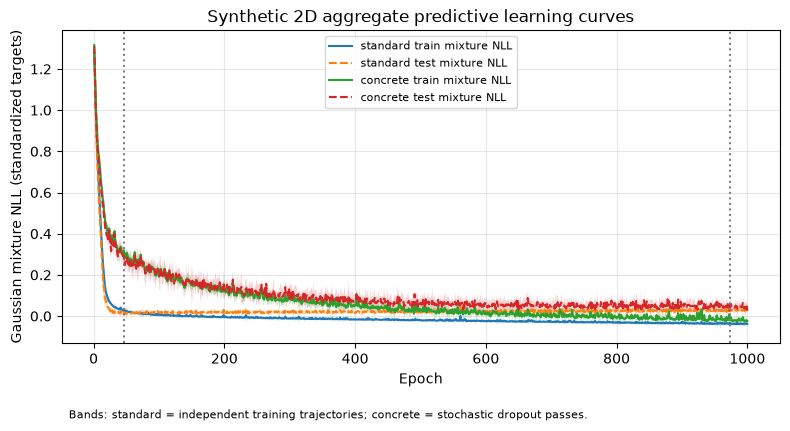

In [119]:

fig, ax = plt.subplots(figsize=(8, 4.5))
for kind in ('standard', 'concrete'):
    curve = syn_fits[kind]['learning_curve']
    epochs_axis = np.arange(1, len(curve['test_mixture_nll']) + 1)
    train_mean = curve['train_mixture_nll']
    test_mean = curve['test_mixture_nll']
    train_std = curve['train_component_std']
    test_std = curve['test_component_std']

    ax.plot(epochs_axis, train_mean, label=f'{kind} train mixture NLL')
    ax.plot(epochs_axis, test_mean, ls='--', label=f'{kind} test mixture NLL')

    ax.fill_between(epochs_axis, train_mean - train_std, train_mean + train_std, alpha=.2)
    ax.fill_between(epochs_axis, test_mean - test_std, test_mean + test_std, alpha=.2)

    best_epoch = int(np.argmin(test_mean))
    ax.axvline(epochs_axis[best_epoch], color='gray', ls=':', alpha=1)
    print(f'{kind:>8} | best epoch {best_epoch+1:3} | mixture test NLL {test_mean[best_epoch]:.3f}')
ax.set(xlabel='Epoch', ylabel='Gaussian mixture NLL (standardized targets)',
       title='Synthetic 2D aggregate predictive learning curves')
ax.text(.01, -.24,
        'Bands: standard = independent training trajectories; '
        'concrete = stochastic dropout passes.',
        transform=ax.transAxes, fontsize=8)
ax.legend(fontsize=8)
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()


## 6. Compare training and test performance as predictive components vary

The table covers the configured member/component counts in `ENSEMBLE_SIZES`, which depend on `N_PREDICTIVE_COMPONENTS`. For the primary matched comparison, the standard ensemble uses the selected number of independently trained members and Concrete Dropout uses the same number of stochastic MC passes from one network. To study MC-pass sensitivity separately, see Section 8.

,Dataset,Method,Members,MC_passes,PredictiveComponents,Split,RMSE,NLL,Coverage90,Width90,AleatoricSD,EpistemicSD
0,synthetic-2d,standard,1,1,1,train,0.304,0.194,0.894,0.976,0.303,0.000
1,synthetic-2d,concrete,1,1,1,train,0.338,0.286,0.921,1.115,0.345,0.000
2,synthetic-2d,standard,1,1,1,test,0.305,0.224,0.893,0.964,0.300,0.000
3,synthetic-2d,concrete,1,1,1,test,0.322,0.282,0.923,1.113,0.345,0.000
4,synthetic-2d,standard,2,1,2,train,0.304,0.189,0.898,0.965,0.299,0.024
5,synthetic-2d,concrete,1,2,2,train,0.325,0.239,0.934,1.141,0.346,0.096
6,synthetic-2d,standard,2,1,2,test,0.302,0.216,0.885,0.956,0.296,0.024
7,synthetic-2d,concrete,1,2,2,test,0.308,0.254,0.939,1.141,0.346,0.093
8,synthetic-2d,standard,3,1,3,train,0.303,0.181,0.904,0.978,0.302,0.032
9,synthetic-2d,concrete,1,3,3,train,0.319,0.238,0.936,1.153,0.346,0.113


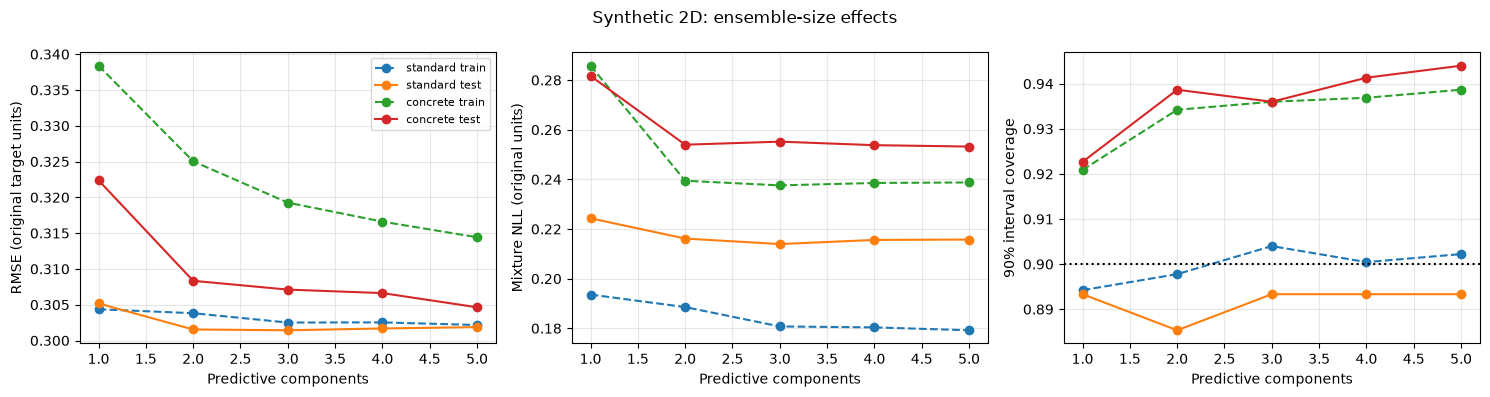

In [116]:
def comparison_table(fits, ds, mc=MC_SAMPLES):
    rows=[]
    for M in ENSEMBLE_SIZES:
        for split in ('train','test'):
            rows.append(dict(Dataset=ds['name'], Method='standard', Members=M,
                             MC_passes=1, PredictiveComponents=M, Split=split,
                             **evaluate(fits['standard']['models'][:M], ds, split, mc=1)))
            rows.append(dict(Dataset=ds['name'], Method='concrete', Members=1,
                             MC_passes=M, PredictiveComponents=M, Split=split,
                             **evaluate(fits['concrete']['models'], ds, split, mc=M)))
    return pd.DataFrame(rows)

syn_table = comparison_table(syn_fits, syn)
display(syn_table.round(3))

def plot_metrics(table, title):
    fig, axs = plt.subplots(1, 3, figsize=(15, 4))
    for kind in ('standard','concrete'):
        for split, style in [('train','--'), ('test','-')]:
            part = table[(table.Method==kind)&(table.Split==split)].sort_values('PredictiveComponents')
            for ax, metric in zip(axs, ('RMSE','NLL','Coverage90')):
                ax.plot(part.PredictiveComponents, part[metric], marker='o', ls=style, label=f'{kind} {split}')
    axs[0].set_ylabel('RMSE (original target units)')
    axs[1].set_ylabel('Mixture NLL (original units)')
    axs[2].set_ylabel('90% interval coverage')
    axs[2].axhline(.9, ls=':', color='black', label='Nominal 90%')
    for ax in axs: ax.set_xlabel('Predictive components'); ax.grid(alpha=.3)
    axs[0].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

plot_metrics(syn_table, 'Synthetic 2D: ensemble-size effects')

## 7. Visual uncertainty checks on the synthetic data

Plot predictive mean and uncertainty along a slice ($x_2=0$), and a heatmap of epistemic standard deviation across a grid extending beyond the training square. **Warning:** neural-network uncertainty methods can be overconfident outside the training distribution; uncertainty is not guaranteed to grow with distance from training data.

The epistemic SD is computed as the standard deviation of the predicted means across the predictive components. For the standard method, those components are independently trained networks; for Concrete Dropout, they are stochastic forward passes through one trained network. The calculation is analogous, but the sources of variation—and therefore the interpretation of the uncertainty—are not identical.

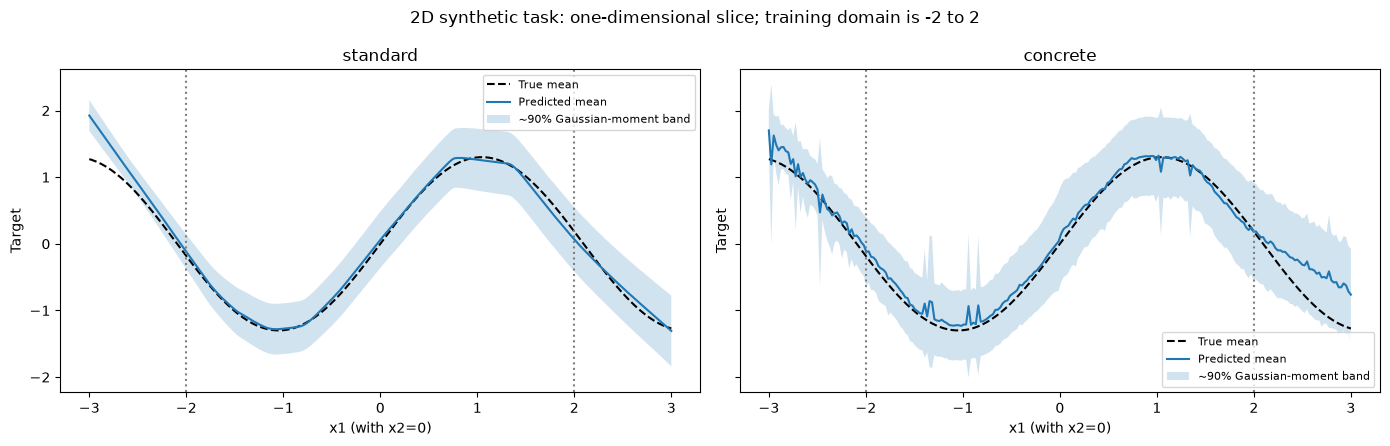

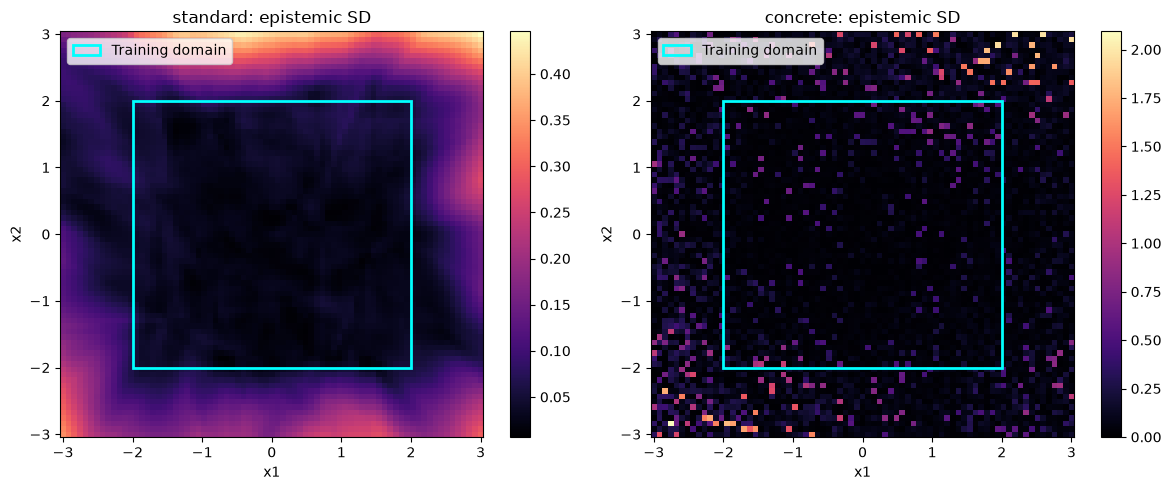

In [117]:
slice_x = np.linspace(-3, 3, 240).astype('float32')
slice_orig = np.column_stack([slice_x, np.zeros_like(slice_x)])
slice_scaled = syn['x_scaler'].transform(slice_orig).astype('float32')
fig, axs=plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, kind in zip(axs, ('standard','concrete')):
    c = component_predictions(syn_fits[kind]['models'], slice_scaled, MC_SAMPLES)
    summary = aggregate(c)
    factor=float(syn['y_scaler'].scale_[0]); center=float(syn['y_scaler'].mean_[0])
    mean = summary['mean']*factor+center
    sd = np.sqrt(summary['total'])*factor
    ax.plot(slice_x, true_mean(slice_orig), color='black', ls='--', label='True mean')
    ax.plot(slice_x, mean, label='Predicted mean')
    ax.fill_between(slice_x, mean-1.64*sd, mean+1.64*sd, alpha=.2, label='~90% Gaussian-moment band')
    ax.axvline(-2, color='gray', ls=':'); ax.axvline(2, color='gray', ls=':')
    ax.set(xlabel='x1 (with x2=0)', title=kind, ylabel='Target')
    ax.legend(fontsize=8)
plt.suptitle('2D synthetic task: one-dimensional slice; training domain is -2 to 2')
plt.tight_layout(); plt.show()

grid_axis=np.linspace(-3,3,75)
gxx, gyy=np.meshgrid(grid_axis,grid_axis)
grid_orig=np.column_stack([gxx.ravel(),gyy.ravel()]).astype('float32')
grid_scaled=syn['x_scaler'].transform(grid_orig).astype('float32')
fig, axs=plt.subplots(1, 2, figsize=(12,5))
for ax, kind in zip(axs, ('standard','concrete')):
    pred=aggregate(component_predictions(syn_fits[kind]['models'], grid_scaled, MC_SAMPLES))
    ep=np.sqrt(pred['epistemic']).reshape(gxx.shape)*float(syn['y_scaler'].scale_[0])
    mesh=ax.pcolormesh(gxx,gyy,ep,shading='auto',cmap='magma')
    ax.add_patch(plt.Rectangle((-2,-2),4,4,fill=False,edgecolor='cyan',lw=2,label='Training domain'))
    ax.set(xlabel='x1',ylabel='x2',title=f'{kind}: epistemic SD')
    ax.legend(loc='upper left'); fig.colorbar(mesh,ax=ax)
plt.tight_layout();plt.show()

## 8. Concrete Dropout: MC forward-pass sensitivity

A single Concrete Dropout member supports $T$ independent stochastic predictions. Check whether increasing $T$ stabilizes error, NLL, interval coverage and epistemic uncertainty. This is **not** the same experiment as increasing $M$ independent model initializations.

,MC_passes,Split,RMSE,NLL,Coverage90,Width90,AleatoricSD,EpistemicSD
0,1,train,0.316,0.215,0.900,1.006,0.313,0.000
1,1,test,0.307,0.241,0.875,0.999,0.312,0.000
2,2,train,0.308,0.184,0.911,1.011,0.313,0.040
3,2,test,0.303,0.225,0.891,1.009,0.311,0.057
4,3,train,0.306,0.181,0.912,1.013,0.313,0.045
5,3,test,0.303,0.226,0.888,1.012,0.312,0.062
6,4,train,0.306,0.181,0.913,1.019,0.313,0.060
7,4,test,0.301,0.226,0.891,1.016,0.311,0.071
8,5,train,0.306,0.181,0.912,1.024,0.313,0.071
9,5,test,0.301,0.226,0.896,1.019,0.312,0.070


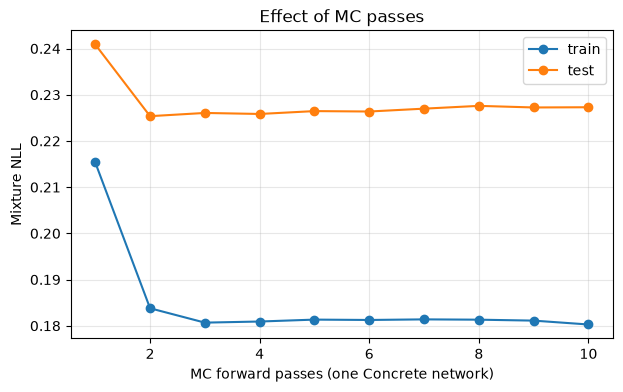

In [120]:
mc_rows=[]
for t in ([i for i in range(1, 11)]):
    for split in ('train','test'):
        mc_rows.append(dict(MC_passes=t, Split=split,
                            **evaluate(syn_fits['concrete']['models'][:1], syn, split, mc=t)))
mc_table=pd.DataFrame(mc_rows)
display(mc_table.round(3))
plt.figure(figsize=(7,4))
for split in ('train','test'):
    p=mc_table[mc_table.Split==split]
    plt.plot(p.MC_passes,p.NLL,marker='o',label=split)
plt.xlabel('MC forward passes (one Concrete network)'); plt.ylabel('Mixture NLL')
plt.title('Effect of MC passes');plt.legend();plt.grid(alpha=.3);plt.show()

## 9. Higher-dimensional realistic dataset: diabetes regression (10 features)

The scikit-learn diabetes dataset has 442 observations and 10 measured predictors. It is small enough for a portable report notebook but realistic and more challenging than a synthetic function. We use a **fixed train/test split** and train-standardization; no test labels or fitted test statistics are used during training. Metrics are transformed back to original target units for interpretability.

In [140]:
EPOCHS_REAL = 40
real_fits=fit_collection(real,EPOCHS_REAL)

 diabetes-10d | standard | seed  11 | final train/test NLL 0.852/1.091
 diabetes-10d | standard | seed  23 | final train/test NLL 0.832/1.143
 diabetes-10d | standard | seed  37 | final train/test NLL 0.802/1.224
 diabetes-10d | standard | seed  51 | final train/test NLL 0.846/1.175
 diabetes-10d | standard | seed  71 | final train/test NLL 0.840/1.156
 diabetes-10d | concrete | seed  11 | final train/test NLL 0.964/1.079 | dropout [0.0935, 0.1036]
Training finished in 1.5 seconds


standard | best epoch  12 | mixture test NLL 1.045
concrete | best epoch  36 | mixture test NLL 0.990


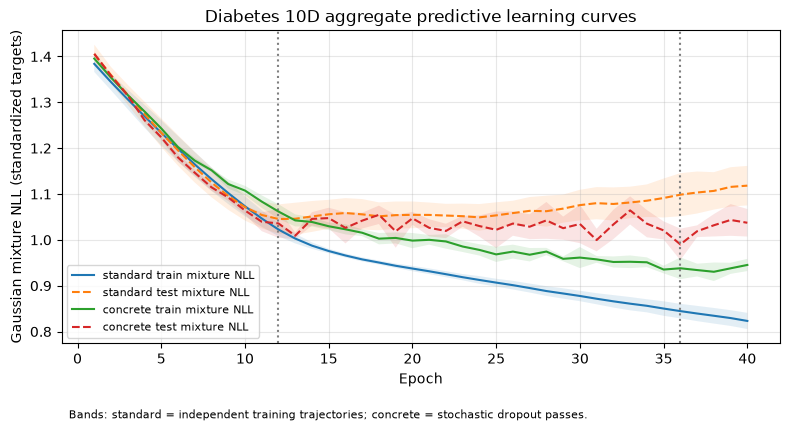

In [141]:

fig, ax = plt.subplots(figsize=(8,4.5))
fits, title = real_fits, 'Diabetes 10D'
for kind in ('standard','concrete'):
    curve=fits[kind]['learning_curve']
    epochs_axis=np.arange(1, len(curve['test_mixture_nll'])+1)
    train_mean, train_std=curve['train_mixture_nll'], curve['train_component_std']
    test_mean, test_std=curve['test_mixture_nll'], curve['test_component_std']
    ax.plot(epochs_axis, train_mean, label=f'{kind} train mixture NLL')
    ax.fill_between(epochs_axis, train_mean-train_std, train_mean+train_std, alpha=.12)
    ax.plot(epochs_axis, test_mean, ls='--', label=f'{kind} test mixture NLL')
    ax.fill_between(epochs_axis, test_mean-test_std, test_mean+test_std, alpha=.12)
    best_epoch=int(np.argmin(test_mean))
    print(f'{kind:>8} | best epoch {best_epoch+1:3} | mixture test NLL {test_mean[best_epoch]:.3f}')
    ax.axvline(epochs_axis[best_epoch], color='gray', ls=':', alpha=1)
ax.set(xlabel='Epoch',ylabel='Gaussian mixture NLL (standardized targets)',title=f'{title} aggregate predictive learning curves')
ax.text(.01, -.24, 'Bands: standard = independent training trajectories; concrete = stochastic dropout passes.', transform=ax.transAxes, fontsize=8)
ax.legend(fontsize=8);ax.grid(alpha=.3)
plt.tight_layout();plt.show()

,Dataset,Method,Members,MC_passes,PredictiveComponents,Split,RMSE,NLL,Coverage90,Width90,AleatoricSD,EpistemicSD
0,diabetes-10d,standard,1,1,1,train,52.845,5.334,0.885,167.697,51.888,0.000
1,diabetes-10d,concrete,1,1,1,train,55.880,5.398,0.915,178.398,55.156,0.000
2,diabetes-10d,standard,1,1,1,test,54.097,5.382,0.883,163.685,50.610,0.000
3,diabetes-10d,concrete,1,1,1,test,53.861,5.361,0.937,174.212,53.804,0.000
4,diabetes-10d,standard,2,1,2,train,52.195,5.317,0.900,166.105,50.964,6.628
5,diabetes-10d,concrete,1,2,2,train,54.754,5.381,0.924,181.051,55.083,8.953
6,diabetes-10d,standard,2,1,2,test,54.087,5.377,0.874,162.347,49.642,7.685
7,diabetes-10d,concrete,1,2,2,test,54.913,5.382,0.919,177.983,53.914,10.405
8,diabetes-10d,standard,3,1,3,train,51.842,5.315,0.915,166.609,51.025,7.313
9,diabetes-10d,concrete,1,3,3,train,54.413,5.368,0.924,181.953,55.087,10.600


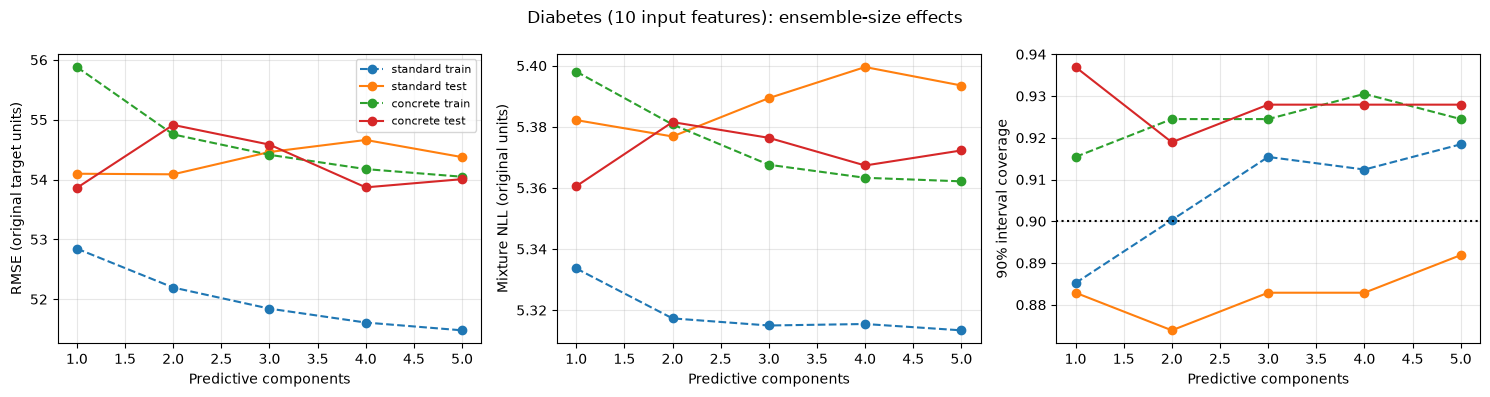

In [136]:
real_table=comparison_table(real_fits,real)
display(real_table.round(3))
plot_metrics(real_table,'Diabetes (10 input features): ensemble-size effects')

## 10. Learned dropout rates and compact result table

Training curves plot one stochastic Concrete evaluation per epoch and therefore may appear noisier than the deterministic ensemble members. Test curves are **diagnostic only**: do not select hyperparameters or epochs based on the test set in a formal experiment; split a validation set from the training data for tuning.

In [ ]:
rates=[]
for ds_name,fits in [('synthetic-2d',syn_fits),('diabetes-10d',real_fits)]:
    for seed,model in [(CONCRETE_SEED, fits['concrete']['models'][0])]:
        rates.append(dict(Dataset=ds_name,Seed=seed,
                          Layer1_dropout=model.dropout_rates()[0],Layer2_dropout=model.dropout_rates()[1]))
display(pd.DataFrame(rates).round(4))
summary=pd.concat([syn_table,real_table],ignore_index=True)
summary=summary[(summary.Split=='test')&(summary.PredictiveComponents.isin([1,5]))]
display(summary.round(3))

,Dataset,Seed,Layer1_dropout,Layer2_dropout
0,synthetic-2d,11,0.0033,0.0046
1,diabetes-10d,11,0.0990,0.1033


,Dataset,Method,Members,MC_passes,PredictiveComponents,Split,RMSE,NLL,Coverage90,Width90,AleatoricSD,EpistemicSD
2,synthetic-2d,standard,1,1,1,test,0.305,0.224,0.893,0.964,0.300,0.000
3,synthetic-2d,concrete,1,1,1,test,0.322,0.282,0.923,1.113,0.345,0.000
18,synthetic-2d,standard,5,1,5,test,0.302,0.216,0.893,0.966,0.298,0.035
19,synthetic-2d,concrete,1,5,5,test,0.305,0.253,0.944,1.170,0.346,0.121
22,diabetes-10d,standard,1,1,1,test,54.097,5.382,0.883,163.685,50.610,0.000
23,diabetes-10d,concrete,1,1,1,test,53.861,5.361,0.937,174.212,53.804,0.000
38,diabetes-10d,standard,5,1,5,test,54.375,5.394,0.892,167.014,50.635,8.686
39,diabetes-10d,concrete,1,5,5,test,54.006,5.372,0.928,178.703,53.746,11.612


## 11. Report discussion / interpretation checklist

After executing the notebook, use the generated plots and tables to address:

1. **Synthetic validation:** Do the predictive means follow the true function? Does modeled noise account for the known input-dependent standard deviation? Compare aleatoric uncertainty to `true_std` on in-domain held-out points.
2. **Predictive components:** How do RMSE, mixture NLL, 90% coverage, and epistemic SD change from 1 to 5 matched predictive components? For the standard method, these are independently trained members; for Concrete Dropout, they are stochastic passes from one network. Look for diminishing returns and distinguish the sources of diversity.
3. **Method comparison:** Does learned Concrete Dropout improve calibration or NLL over standard ensembling? Does it underestimate/overestimate interval widths? Compare both with matched member counts, and report MC passes separately.
4. **Training vs test:** Are train errors substantially smaller than test errors? Is uncertainty larger for out-of-distribution regions? Do not interpret that relationship as universally guaranteed.
5. **10D realistic task:** Does the relative ranking change on diabetes? Why might limited data, covariate correlation, or Gaussian output assumptions matter?
6. **Limitations:** Both methods use a Gaussian observation likelihood, layer-wise Concrete probabilities depend on prior/entropy strengths, and five seeds are a relatively small sample. The same test set is reused for descriptive plots: do not treat it as a source of tuned hyperparameters.

**Optional extensions:** a validation split for selecting epochs and regularization; a second synthetic dataset with two distinct conditional modes (Gaussian output heads will struggle); repeated random train/test splits and confidence intervals; stronger/weaker L2 priors; calibration curves by interval level; alternative Concrete temperature values.

### Suggested references

- Lakshminarayanan, Pritzel & Blundell (2017), *Simple and Scalable Predictive Uncertainty Estimation using Deep Ensembles*, NeurIPS. https://arxiv.org/abs/1612.01474
- Gal, Hron & Kendall (2017), *Concrete Dropout*, NeurIPS. https://arxiv.org/abs/1705.07832
- Gal & Ghahramani (2016), *Dropout as a Bayesian Approximation: Representing Model Uncertainty in Deep Learning*, ICML. https://arxiv.org/abs/1506.02142

**Reproducibility note:** All training seeds and split seeds are fixed in code. CUDA/GPU execution may still show minor nondeterminism depending on backend operations.